In [ ]:
import requests
from bs4 import BeautifulSoup
import json

import polars as pl

import plotnine as gg
from plotnine import ggplot, aes

In [97]:
s = requests.Session()

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/143.0.0.0 Safari/537.36',
    'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7',
    'Accept-Language': 'pt-BR,pt;q=0.9,en-US;q=0.8,en;q=0.7,es-ES;q=0.6,es;q=0.5',
    'Content-Type': 'application/x-www-form-urlencoded',
    'Connection': 'keep-alive',
    'Upgrade-Insecure-Requests': '1'
}

s = requests.Session()
s.headers.update(headers)

In [98]:
url = "https://pollingdata.com.br/capa2025/previsao_2025_historico.html"

request_get = s.get(url)

if request_get.status_code != 200:
    raise Exception("Failed to fetch countries")

soup = BeautifulSoup(request_get.content)

soup_json_lula3 = soup.select_one("#lula-3º > script[data-for=gov_lula3]")

if not soup_json_lula3:
    raise Exception("Failed to find the JSON data script tag")

json_data = json.loads(soup_json_lula3.string)

In [99]:
print("- Analyzing JSON structure:")
print(json_data.keys())
print(json_data['x'].keys())
print(json_data['x']['hc_opts'].keys())

series = json_data['x']['hc_opts']['series']

print("\n- Analysing series keys:")
for i in range(len(series)):
    print(series[i]['data'][0].keys())

- Analyzing JSON structure:
dict_keys(['x', 'evals', 'jsHooks'])
dict_keys(['hc_opts', 'theme', 'conf_opts', 'type', 'fonts', 'debug'])
dict_keys(['chart', 'title', 'yAxis', 'credits', 'exporting', 'boost', 'plotOptions', 'series', 'xAxis', 'tooltip', 'navigator', 'legend'])

- Analysing series keys:
dict_keys(['presidente', 'semana', 'proposicoes', 'votacoes', 'votantes', 'data_fim', 'voto.gov', 'voto.part', 'proposicoes.cum', 'votacoes.cum', 'votantes.cum', 'voto.gov.cum', 'voto.part.cum', 'categ', 'x', 'y', 'z', 'name', 'url', 'high', 'low', 'int'])
dict_keys(['presidente', 'semana', 'proposicoes', 'votacoes', 'votantes', 'data_fim', 'voto.gov', 'voto.part', 'proposicoes.cum', 'votacoes.cum', 'votantes.cum', 'voto.gov.cum', 'voto.part.cum', 'categ', 'x', 'y', 'z', 'name', 'url', 'high', 'low', 'int'])
dict_keys(['presidente', 'semana', 'votacoes', 'data', 'proposicao_id', 'proposicao_titulo', 'idVotacao', 'orientacao_gov', 'status', 'sim', 'nao', 'abst', 'total', 'descricao', 'url.t

In [ ]:
series_datasets = []

for i in range(len(series)):
    dataset = pl.DataFrame(series[i]['data'])
    dataset = dataset.with_columns(
        pl.lit(str(i)).alias('position_within_json')
    )
    # Identifier of where was series located in the original JSON
    series_datasets.append(dataset)

data_interval = pl.concat(series_datasets[:2]) # Confidence interval
data_points = pl.concat(series_datasets[2:]) # Individual points

# Format date column:
data_points = data_points.with_columns(
    pl.col('data').str.strptime(pl.Date, "%Y-%m-%d", strict = False)
)

c:\Python310\lib\site-packages\plotnine\scales\scale_datetime.py:97: FutureWarning: Passing a string to `labels` will not work in future versions. Use `date_labels='%Y-%m'`


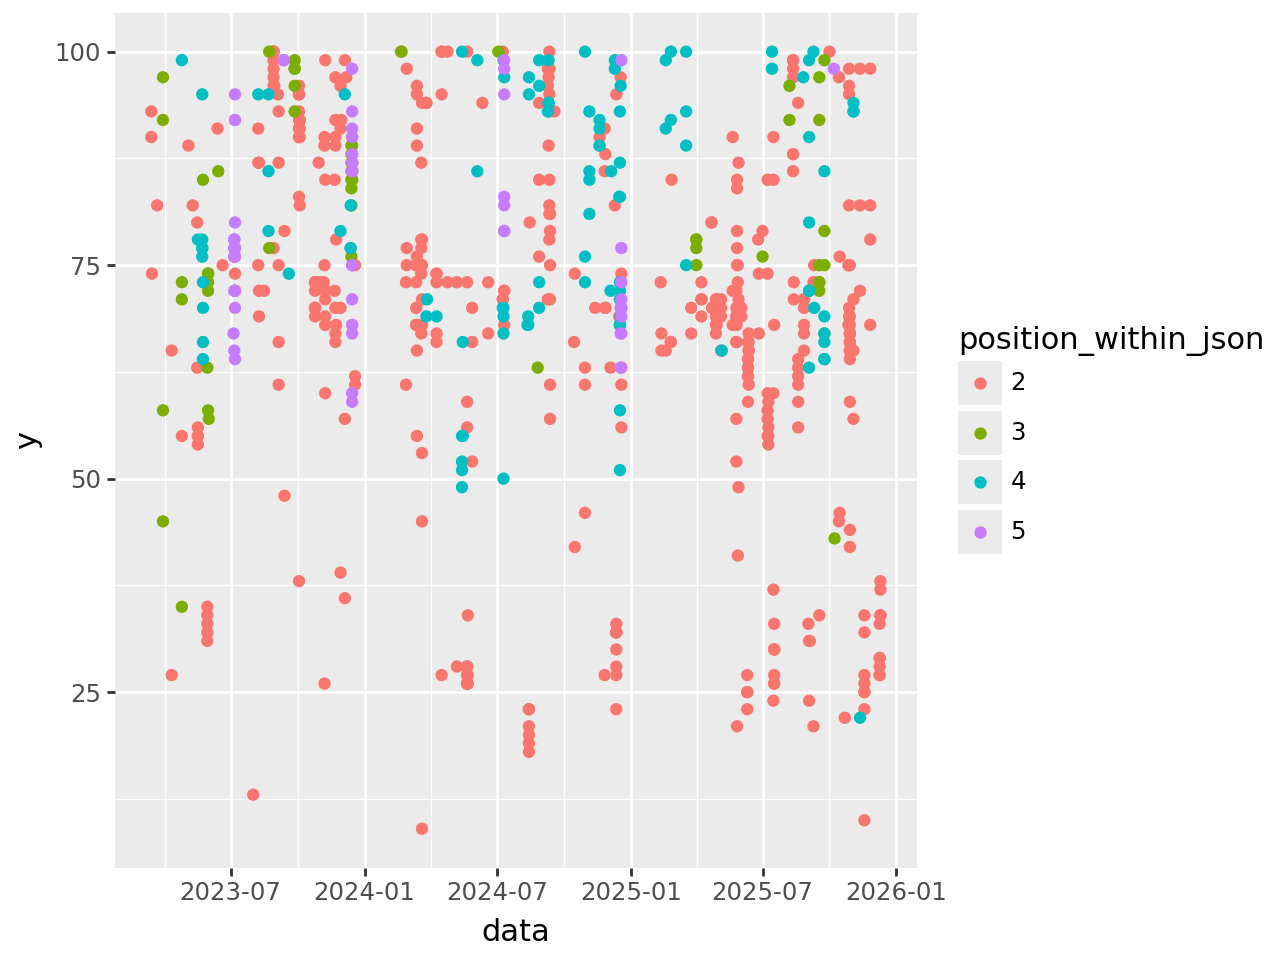

In [101]:
# Graph sketch:
(
    ggplot(data_points, aes('data', 'y', color = 'position_within_json')) +
        gg.geom_point() +
        gg.scale_x_date(labels = "%Y-%m")
)